In [86]:
import sys, os
sys.path.append("..")
import usf

In [87]:
usf_folders = ['C:/Users/au646858/Downloads/USF_Files_dawa river/',
               #'/home/matt/geophysics_data/TEM/sTEM_data/2025_0302/USF_Files_dawa river 3/']
            ]

sweeps = []
for usf_folder in usf_folders:
    usf_files = [usf_folder+f for f in os.listdir(usf_folder) if f.endswith('.usf')]
    for usf_file in usf_files:        
        sweeps += usf.Sweep.from_usf(usf_file, combine=False)

data_overview, df_data = usf.sweep2dataframes(sweeps)

# df_data.loc[df_data['time']>1e-3, 'inuse_auto'] = False
# df_data = df_data.sort_values(by=['site_id','system_id', 'gate_id'])

In [88]:
points = set([x.points for x in sweeps])

mega_sweeps = []
for pnts in points:
    mega_sweeps.append(usf.Sweep.combine_sweeps([swp for swp in sweeps if swp.points==pnts]))
lm,hm = mega_sweeps

In [89]:
df_data['include'] = df_data['inuse_auto']

In [90]:
pivot = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values='dbdt'
)

In [91]:
# Create pivot table with multiple values
pivot_multi = df_data[df_data['site_id']>=0].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include']
)

# Flatten the multi-level column names
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
pivot_multi

,dbdt_0.0,dbdt_0.01,dbdt_0.02,dbdt_0.03,dbdt_0.04,dbdt_0.05,dbdt_1.0,dbdt_1.01,dbdt_1.02,dbdt_1.03,...,include_1.12,include_1.13,include_1.1400000000000001,include_1.15,include_1.16,include_1.17,include_1.18,include_1.19,include_1.2,include_1.21
site_id,,,,,,,,,,,,,,,,,,,,,
0,0.000008,0.000005,2.960390e-06,1.716670e-06,9.905290e-07,5.755000e-07,1.246170e-06,6.747170e-07,3.695650e-07,2.045410e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,0.000005,0.000003,1.777440e-06,1.070710e-06,6.543040e-07,4.038660e-07,8.063070e-07,4.697770e-07,2.770680e-07,1.646370e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,0.000004,0.000003,1.760430e-06,1.135900e-06,7.274330e-07,4.618690e-07,8.772410e-07,5.313900e-07,3.197160e-07,1.914410e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,0.000006,0.000004,2.421000e-06,1.522140e-06,9.499710e-07,5.866660e-07,1.156850e-06,6.788090e-07,3.943070e-07,2.269800e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,0.000004,0.000002,1.545860e-06,9.725170e-07,6.080860e-07,3.786440e-07,7.421770e-07,4.394710e-07,2.611980e-07,1.562060e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,0.000002,0.000001,9.014080e-07,5.925550e-07,3.889980e-07,2.556770e-07,4.679400e-07,2.939610e-07,1.851020e-07,1.167700e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,0.000004,0.000002,1.409740e-06,8.513620e-07,5.201450e-07,3.211830e-07,6.428770e-07,3.743210e-07,2.214700e-07,1.328950e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,0.000006,0.000004,2.039370e-06,1.177080e-06,6.872580e-07,4.058750e-07,8.644760e-07,4.780200e-07,2.697180e-07,1.551280e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,0.000004,0.000002,1.316900e-06,8.128670e-07,5.068250e-07,3.182930e-07,6.204600e-07,3.692040e-07,2.225660e-07,1.354880e-07,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [114]:
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.forwards import Forward

import numpy as np

def sweep2fwr(sweeps, fwr=Forward):
    points = set(swp.points for swp in sweeps)
    forwards = []
    for pnts in points:
        swp = next(swp for swp in sweeps if swp.points == pnts)
        tx = Loop.square(swp.loop_size[0])
        rx = Receiver(x=swp.coil_location[0], y=swp.coil_location[1])
        wv = Waveform(swp.tx_ramp_time, swp.tx_ramp)
        filter_chain = []

        for f_cut, order in zip(swp.low_pass[::2], swp.low_pass[1::2]):
            filter_chain.append(ButterworthFilter(f_cut))
        fc = FilterChain(filter_chain)
        time = swp.time
        forwards.append(fwr(tx, rx, time, wv, fc, tolerance=1e-6))
    return forwards

In [176]:
import matplotlib.pyplot as plt
from anemone.inversion import *
from anemone.forwards import *
import torch

logForward = logify_forward(Forward)
fwrs = sweep2fwr(sweeps, fwr=logForward)

fwrs[0].source = fwrs[1].source
fwrs[0].receiver = fwrs[1].receiver
fwrs[0].filterfunc = fwrs[1].filterfunc

dmfwr = fwrs[0]+fwrs[1]


rho = torch.tensor([20, 10, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**dmfwr(rho, thk)

res_start = LogResistivity.smooth(torch.ones(31, dtype=torch.double)*50, torch.logspace(0, 2, 30))
fastJac = fastjacobian(Tikhonov)

In [177]:
data_overview, df_data = usf.sweep2dataframes(sweeps)

df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]
row = pivot_multi.loc[15]

dbdt_values  = row.filter(like='dbdt_').values
error_values = row.filter(like='error_').values
include_values = row.filter(like='include_').values.astype(bool)

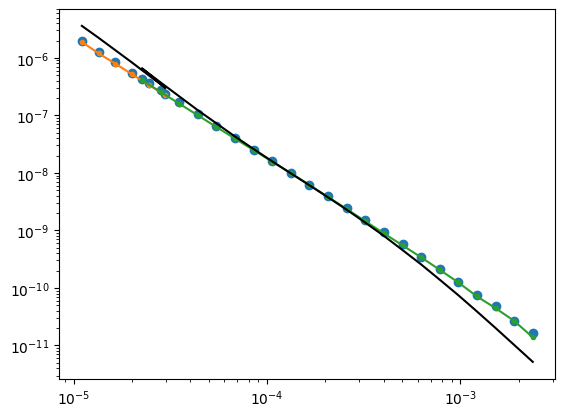

In [178]:
d_obs = torch.from_numpy(dbdt_values).abs()#.log10()

# d_true = 10**torch.concat([fwr(rho, thk) for fwr in fwrs])
# d_time = torch.concat([fwr.times for fwr in fwrs])

plt.figure()
plt.loglog(dmfwr.times, d_obs, 'o', label='Observed Data')
plt.plot(lm.time[14], lm.data[14], '.-')
plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**dmfwr(rho,thk), 'k-', label='True Model')

In [179]:
d_obs = torch.from_numpy(dbdt_values).abs().log10()
d_err = torch.from_numpy(np.log10(1. + error_values/100.))

include_mask = include_values.astype(bool)
d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

inv = fastJac(d_obs, d_err, res_start, dmfwr)
inv.data_misfit_acceptance_threshold = 1.
res_mod = inv.invert(iter_cap=10)

001	misfit:	13.65
002	misfit:	3.51
003	misfit:	1.67
004	misfit:	1.24
005	misfit:	1.03
006	misfit:	0.90
misfit is below 1.0, stopping inversion


In [180]:
d_syn = inv.forward(*res_mod.mod)

In [181]:
d_syn

tensor([ -5.7036,  -5.8931,  -6.0820,  -6.2669,  -6.4548,  -6.6418,  -6.3470,
         -6.5544,  -6.7608,  -6.9700,  -7.1765,  -7.3875,  -7.5951,  -7.8041,
         -8.0104,  -8.2136,  -8.4160,  -8.6141,  -8.8168,  -9.0187,  -9.2300,
         -9.4437,  -9.6677,  -9.8960, -10.1331, -10.3766, -10.6272, -10.8842],
       dtype=torch.float64)

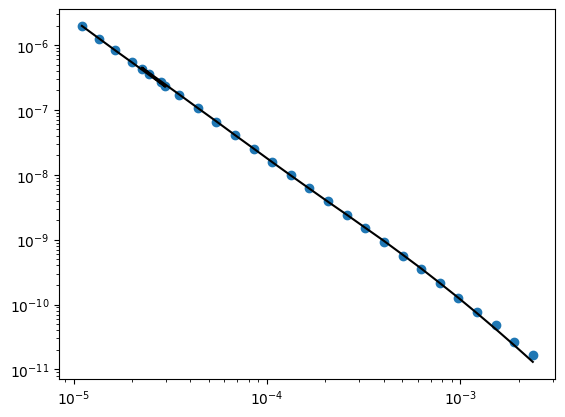

In [182]:
plt.figure()
plt.loglog(dmfwr.times, 10**d_obs, 'o', label='Observed Data')
# plt.plot(lm.time[14], lm.data[14], '.-')
# plt.plot(hm.time[14], hm.data[14], '.-')
plt.plot(dmfwr.times, 10**d_syn, 'k-', label='True Model')

In [183]:
import pandas as pd

def silence(s):
    pass

data_overview, df_data = usf.sweep2dataframes(sweeps)
df_overview = df_res.pivot_table(
    index=['site_id'],
    values=['date', 'daytime', 'latitude', 'longitude', 'elevation'],
    aggfunc='first'
)


df_data['include'] = df_data['inuse_auto']

df_res = df_data.copy()
df_res['dbdt_syn'] = df_res['dbdt']*np.nan

pivot_multi = df_data[(df_data['site_id']>-1)*(df_data['gate_id']>-1)].pivot_table(
    index=['site_id'],
    columns=['sys_gate'],
    values=['dbdt', 'error', 'include', 'data_id'],
)
pivot_multi.columns = [f'{val}_{col}' for val, col in pivot_multi.columns]

assert len(pivot_multi) == len(df_overview), "Expected 4 columns in pivot_multi"

pivot_multi.sort_values(by='site_id', inplace=True)
df_overview.sort_values(by='site_id', inplace=True)

In [184]:
results = []
for i,(row,row_meta) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    if i==1:
        print(row)
        print(row_meta)

(1, data_id_0.0     61.0
data_id_0.01    62.0
data_id_0.02    63.0
data_id_0.03    64.0
data_id_0.04    65.0
                ... 
include_1.17     1.0
include_1.18     1.0
include_1.19     1.0
include_1.2      1.0
include_1.21     1.0
Name: 1, Length: 112, dtype: float64)
(1, date         2.025023e+07
daytime      1.218500e+01
elevation    1.900000e+02
latitude     4.146311e+00
longitude    4.206047e+01
Name: 1, dtype: float64)


In [185]:
results = []
inv_list = []

for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    dbdt_values  = row.filter(like='dbdt_').values
    error_values = row.filter(like='error_').values
    include_values = row.filter(like='include_').values
    data_id = row.filter(like='data_id_').values

    d_obs = torch.from_numpy(dbdt_values).abs().log10()
    d_err = torch.from_numpy(np.log10(1. + error_values/100.))
    include_mask = include_values.astype(bool)
    d_err[~include_mask] = torch.inf  # Set error to zero for included measurements

    inv = fastJac(d_obs, d_err, res_start, dmfwr, logger=silence)
    inv.smoothness_vert = 0.4
    inv.setup_matrices()
    inv_list.append(inv)
    # inv.invert(iter_cap=20)
    # print(i)
    

In [186]:
torch.set_num_threads(8)

import utm
utmx,utmy,zone_number,zone_letter = utm.from_latlon(df_overview['latitude'].values, df_overview['longitude'].values)
df_overview['utm_x'] = utmx
df_overview['utm_y'] = utmy
df_overview['zone_number'] = zone_number
df_overview['zone_letter'] = zone_letter

inv = SCI(inv_list, x= df_overview['utm_x'].values, y=df_overview['utm_y'].values)
inv.data_misfit_acceptance_threshold = 0.95
inv.smoothness_vert = 0.3
inv.smoothness_lat = 0.3
res_mods = inv.invert(iter_cap=10)

Number of attempts to reduce damping: 20
001	misfit:	10.81
Number of attempts to reduce damping: 20
002	misfit:	8.55
Number of attempts to reduce damping: 20
003	misfit:	7.23
Number of attempts to reduce damping: 20
004	misfit:	6.21
Number of attempts to reduce damping: 20
005	misfit:	5.45
Number of attempts to reduce damping: 0
006	misfit:	4.83
Number of attempts to reduce damping: 0
007	misfit:	4.32
Number of attempts to reduce damping: 20
008	misfit:	3.89
Number of attempts to reduce damping: 0
009	misfit:	3.53
Number of attempts to reduce damping: 20
010	misfit:	3.23
reached iteration cap..


In [187]:
for i,((id_row, row), (id_meta, row_meta)) in enumerate(zip(pivot_multi.iterrows(), df_overview.iterrows())):
    assert id_meta == id_row, "Site ID mismatch between row and metadata"

    data_id = row.filter(like='data_id_').values    
    res_mod = res_mods[i].copy()

    d_syn = 10**inv_list[i].forward(*res_mod.mod)
    print(d_syn)
    df_res.loc[data_id, 'dbdt_syn'] = d_syn.numpy()

    rho,thick = res_mod.mod
    row_meta['site_id'] = id_meta
    row_meta['resistivity'] = rho.detach().cpu().numpy().tolist()
    row_meta['thickness'] = thick.detach().cpu().numpy().tolist()
    results.append(row_meta.to_dict())
    print(f'Inversion for data_id {i:02d} completed.')

df_resmod = pd.DataFrame(results)

tensor([7.6930e-06, 4.8471e-06, 2.9414e-06, 1.7665e-06, 1.0367e-06, 6.0943e-07,
        1.3802e-06, 7.6126e-07, 4.2106e-07, 2.3084e-07, 1.2976e-07, 7.2177e-08,
        4.1322e-08, 2.3669e-08, 1.3750e-08, 8.0417e-09, 4.6874e-09, 2.7657e-09,
        1.6088e-09, 9.5564e-10, 5.5947e-10, 3.3498e-10, 1.9903e-10, 1.1953e-10,
        7.1305e-11, 4.2374e-11, 2.4883e-11, 1.4481e-11], dtype=torch.float64)
Inversion for data_id 00 completed.
tensor([5.1815e-06, 3.1327e-06, 1.8699e-06, 1.1283e-06, 6.7429e-07, 4.0849e-07,
        8.9200e-07, 5.0759e-07, 2.9348e-07, 1.7037e-07, 1.0148e-07, 6.0171e-08,
        3.6327e-08, 2.1844e-08, 1.3175e-08, 7.9404e-09, 4.7475e-09, 2.8578e-09,
        1.6948e-09, 1.0200e-09, 6.0330e-10, 3.6178e-10, 2.1392e-10, 1.2690e-10,
        7.4347e-11, 4.3194e-11, 2.4755e-11, 1.4024e-11], dtype=torch.float64)
Inversion for data_id 01 completed.
tensor([4.4348e-06, 2.8556e-06, 1.8262e-06, 1.1670e-06, 7.3389e-07, 4.5989e-07,
        9.5004e-07, 5.6531e-07, 3.3550e-07, 1.9709e-

In [188]:
df_res.to_csv('inversion_SCI_results.csv')
#df_res


In [189]:
df_resmod
rows = []
for _, row in df_resmod.iterrows():
    site_id = row['site_id']
    resistivities = row['resistivity']
    thicknesses = row['thickness']
    # Compute top and bottom depths
    tops = np.concatenate([[0], np.cumsum(thicknesses)[:-1]])
    bottoms = np.cumsum(thicknesses)
    for i, (rho, top, bottom) in enumerate(zip(resistivities, tops, bottoms)):
        rows.append({
            'site_id': site_id,
            'daytime': row['daytime'],
            'date': row['date'],
            'latitude': row['latitude'],
            'longitude': row['longitude'],
            'elevation': row['elevation'],
            'layer': i,
            'resistivity': rho,
            'top_depth': top,
            'bottom_depth': bottom,
            'center_depth': (top + bottom) / 2
        })

df_layers = pd.DataFrame(rows)
df_layers.to_csv("inversion_SCI_results_models.csv", index=False)

In [171]:
df_res

,site_id,dbdt,error,inuse_auto,inuse_manual,time,gate_id,system_id,date,latitude,longitude,elevation,daytime,error_lb,error_ub,log10_dbdt,sys_gate,data_id,include,dbdt_syn
0,-1,NaN,NaN,True,NaN,NaN,-1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.01,0,True,NaN
1,-1,NaN,NaN,True,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,1,True,NaN
2,-1,NaN,NaN,True,NaN,NaN,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01,2,True,NaN
3,-1,NaN,NaN,True,NaN,NaN,2,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,3,True,NaN
4,-1,NaN,NaN,True,NaN,NaN,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.03,4,True,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1525,49,1.790430e-10,3.24,True,NaN,0.000975,17,1,20250227.0,4.157496,42.063432,176.0,13.71694,5.618940e-12,5.800993e-12,-9.747043,1.17,1525,True,1.683656e-10
1526,49,1.071470e-10,3.62,True,NaN,0.001217,18,1,20250227.0,4.157496,42.063432,176.0,13.71694,3.743217e-12,3.878721e-12,-9.970020,1.18,1526,True,9.873422e-11
1527,49,5.942610e-11,4.62,True,NaN,0.001519,19,1,20250227.0,4.157496,42.063432,176.0,13.71694,2.624246e-12,2.745486e-12,-10.226023,1.19,1527,True,5.683675e-11
1528,49,3.443000e-11,6.69,True,NaN,0.001897,20,1,20250227.0,4.157496,42.063432,176.0,13.71694,2.158934e-12,2.303367e-12,-10.463063,1.20,1528,True,3.207996e-11


In [172]:
import plotly.express as px

fig = px.line(
    df_layers,
    x="resistivity",
    y="center_depth",
    color="site_id",
    # markers=True,
    labels={
        "resistivity": "Resistivity [Ω·m]",
        "center_depth": "Depth [m]",
        "site_id": "Site ID"
    },
    title="Resistivity vs. Depth by Site"
)

# Reverse y-axis so depth increases downward
fig.update_yaxes(autorange="reversed")
fig.update_layout(
    xaxis_type="log",
)

fig.show()

In [173]:
# ...existing code...
df_layers_long = pd.melt(
    df_layers,
    id_vars=['site_id', 'daytime', 'longitude', 'latitude', 'date', 'elevation', 'layer', 'resistivity'],
    value_vars=['top_depth', 'bottom_depth'],
    var_name='depth_type',
    value_name='depth'
).sort_values(['daytime', 'layer', 'depth'])

# Optional: drop 'depth_type' if you don't need it
df_layers_long = df_layers_long.drop(columns=['depth_type'])

df_layers_long
df_layers_long['z'] = df_layers_long['elevation']-df_layers_long['depth']

In [174]:
import plotly.express as px

fig = px.line(
    df_layers_long,
    x="resistivity",
    y="z",
    color="site_id",
    # markers=True,
    labels={
        "resistivity": "Resistivity [Ω·m]",
        "center_depth": "Depth [m]",
        "site_id": "Site ID"
    },
    title="Resistivity vs. Depth by Site"
)

# Reverse y-axis so depth increases downward
# fig.update_yaxes(autorange="reversed")
fig.update_layout(
    xaxis_type="log",
)

fig.show()

In [175]:
import plotly.express as px

# Pivot the melted DataFrame
df_layers_long['log_resistivity'] = np.log10(df_layers_long['resistivity'])

heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='daytime', values='log_resistivity'
)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()

In [167]:
import plotly.express as px

# Ensure all site_ids are present as columns, even if some are missing
all_site_ids = np.arange(df_layers_long['site_id'].min(), df_layers_long['site_id'].max() + 1)
heatmap_df = df_layers_long.pivot_table(
    index='depth', columns='site_id', values='log_resistivity')
heatmap_df = heatmap_df.reindex(columns=all_site_ids)

# Sort depth so it increases downward
heatmap_df = heatmap_df.sort_index(ascending=True)

fig = px.imshow(
    heatmap_df,
    aspect='auto',
    origin='lower',
    color_continuous_scale='turbo',
    labels={'x': 'Site ID', 'y': 'Depth [m]', 'color': 'log10 Resistivity [Ω·m]'},
    title='Resistivity Heatmap by Site and Depth',
    zmin=heatmap_df.min().min(),
    zmax=heatmap_df.max().max(),
)

fig.update_yaxes(autorange="reversed")
fig.show()